# Hebron: where do the GRD pixels land? (geolocation check)

The GRD σ⁰ files are georeferenced from 16 ground control points. Sentinel-1 GRD is projected onto the ellipsoid, so a point on high ground appears shifted towards the satellite, by about *h* · cot θ, where *h* is its height (above the height the control points assume) and θ the incidence angle. A smooth fit through 16 points cannot follow ridges and valleys a few hundred metres apart. If the shift is large, a change would be assigned to the wrong building.

This notebook measures it, on the files already downloaded, without touching the running download:

1. **Look**: the VV image (mean of the first dates) with building footprints and DEM contours, zoomed into two parts of the city.
2. **Measure**: radar brightness over Hebron is shaped mostly by the terrain (slopes facing the satellite are bright), so the reference is a **brightness simulated from the DEM**: the cosine of the local incidence angle, at the true position of every pixel. The area is cut into tiles; in each, the VV image is cross-correlated with the simulation, giving the shift (east, north) that best aligns them, and the tile's mean height. (A first version correlated the image with building footprints; on real data no tile gave a clear peak, because single houses are not distinct bright targets at 10 m.)
3. **Decide**: the shift is fitted as a + b · height. **b ≈ 0 and a ≈ 0**: aligned, nothing to do. **b ≈ 0, a ≠ 0**: one constant offset, corrected by a shift. **b clearly ≠ 0** (towards the satellite on high ground): terrain distortion, so section 4 of the main notebook needs a terrain correction.

It only reads files; it writes nothing except the footprint file if that is not there yet (the same file the main notebook uses).

In [1]:
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.crs import CRS
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.transform import from_origin
from rasterio.warp import reproject, transform_bounds
from scipy.ndimage import gaussian_filter

DATA = Path("/run/media/samuel-appiah-kubi/New Volume/hebronv5")      # the same folder as the main notebook
BBOX = (35.04, 31.48, 35.18, 31.60)
TRACK_KEY, POL = "D094", "vv"
N_DATES = 5                 # dates averaged (less speckle)
TILE_M, MAX_SHIFT_M = 1600, 400
MIN_BUILT = 0.03            # tiles with less building cover are skipped
MS_LINKS_URLS = ["https://minedbuildings.z5.web.core.windows.net/global-buildings/dataset-links.csv",
                 "https://bfppub.blob.core.windows.net/%24web/2026-08-13/dataset-links.csv"]
sys.path.insert(0, str(Path.cwd()))     # hebron_tools.py, for the footprint download only
SIGMA0_DIR, DEM_DIR, FOOT_DIR, IFG_DIR = DATA / "grd/sigma0", DATA / "dem", DATA / "footprints", DATA / "ifg"
# Viewing geometry of track D094 over Hebron: read from a saved SLC interferogram of the same track when there is one
# (radar geometry of pygeofetch); otherwise these approximate values are used (Sentinel-1 descending, right-looking,
# sub-swath IW1, as in the SLC log): horizontal direction ground -> satellite (east, north) and incidence angle.
TO_SAT_EN, INCIDENCE_DEG = (0.978, -0.208), 34.0

In [2]:
files = sorted((SIGMA0_DIR / TRACK_KEY / POL).glob("*.tif"))
assert files, f"no sigma0 files yet in {SIGMA0_DIR / TRACK_KEY / POL}"
files = files[:N_DATES]
print(f"{len(files)} files:", [f.name for f in files])

GRID_CRS = CRS.from_epsg(32636)
left, bottom, right, top = transform_bounds("EPSG:4326", GRID_CRS, *BBOX)
W10, H10 = int((right - left) // 10), int((top - bottom) // 10)
T10 = from_origin(left, top, 10, 10)


def to_grid(path, resampling=Resampling.bilinear):
    out = np.full((H10, W10), np.nan, "float32")
    with rasterio.open(path) as src:
        reproject(rasterio.band(src, 1), out, src_nodata=src.nodata if src.nodata is not None else np.nan, dst_nodata=np.nan,
                  dst_transform=T10, dst_crs=GRID_CRS, resampling=resampling)
    return out


power = np.nanmean(np.stack([to_grid(f) for f in files]), axis=0)
vv_db = 10 * np.log10(np.where(power > 0, power, np.nan))
with rasterio.open(files[0]) as src:
    print("sigma0 file:", src.crs, "pixel", src.res, "| GCPs kept in the file:", len(src.gcps[0]) if src.gcps[0] else 0)
    if src.gcps[0]:
        z = [g.z for g in src.gcps[0]]
        print("  GCP heights (m):", np.round(z, 1)[:16])

5 files: ['2020-06-06_vv_sigma0_lin_aoib52526.tif', '2020-06-18_vv_sigma0_lin_aoib52526.tif', '2020-07-12_vv_sigma0_lin_aoib52526.tif', '2020-07-24_vv_sigma0_lin_aoib52526.tif', '2020-08-05_vv_sigma0_lin_aoib52526.tif']
sigma0 file: EPSG:4326 pixel (0.0001019935817922682, 0.0001019935817922682) | GCPs kept in the file: 0


In [3]:
fp_path = FOOT_DIR / "ms_buildings.gpkg"
if not fp_path.exists():
    import hebron_tools as ht
    ht.download_ms_footprints(BBOX, MS_LINKS_URLS, fp_path)
fp = gpd.read_file(fp_path)
fp = (fp.set_crs(4326) if fp.crs is None else fp).to_crs(GRID_CRS)
# building cover per 10 m pixel: rasterized at 2 m, averaged over 5 x 5
T2 = from_origin(left, top, 2, 2)
fine = rasterize(((g, 1) for g in fp.geometry), out_shape=(H10 * 5, W10 * 5), transform=T2, fill=0, dtype="uint8")
built = fine.reshape(H10, 5, W10, 5).mean(axis=(1, 3)).astype("float32")
del fine
dem_path = sorted(DEM_DIR.rglob("*COP30*.tif"))[-1]
height = to_grid(dem_path)
height[height < -100] = np.nan
print(f"{len(fp)} footprints; building cover {built.mean():.1%} of the area; DEM {dem_path.name}: "
      f"{np.nanmin(height):.0f}-{np.nanmax(height):.0f} m")

50987 footprints; building cover 7.9% of the area; DEM opentopo_COP30_34.99_31.43_dem.tif: 531-1022 m


## 1. Look

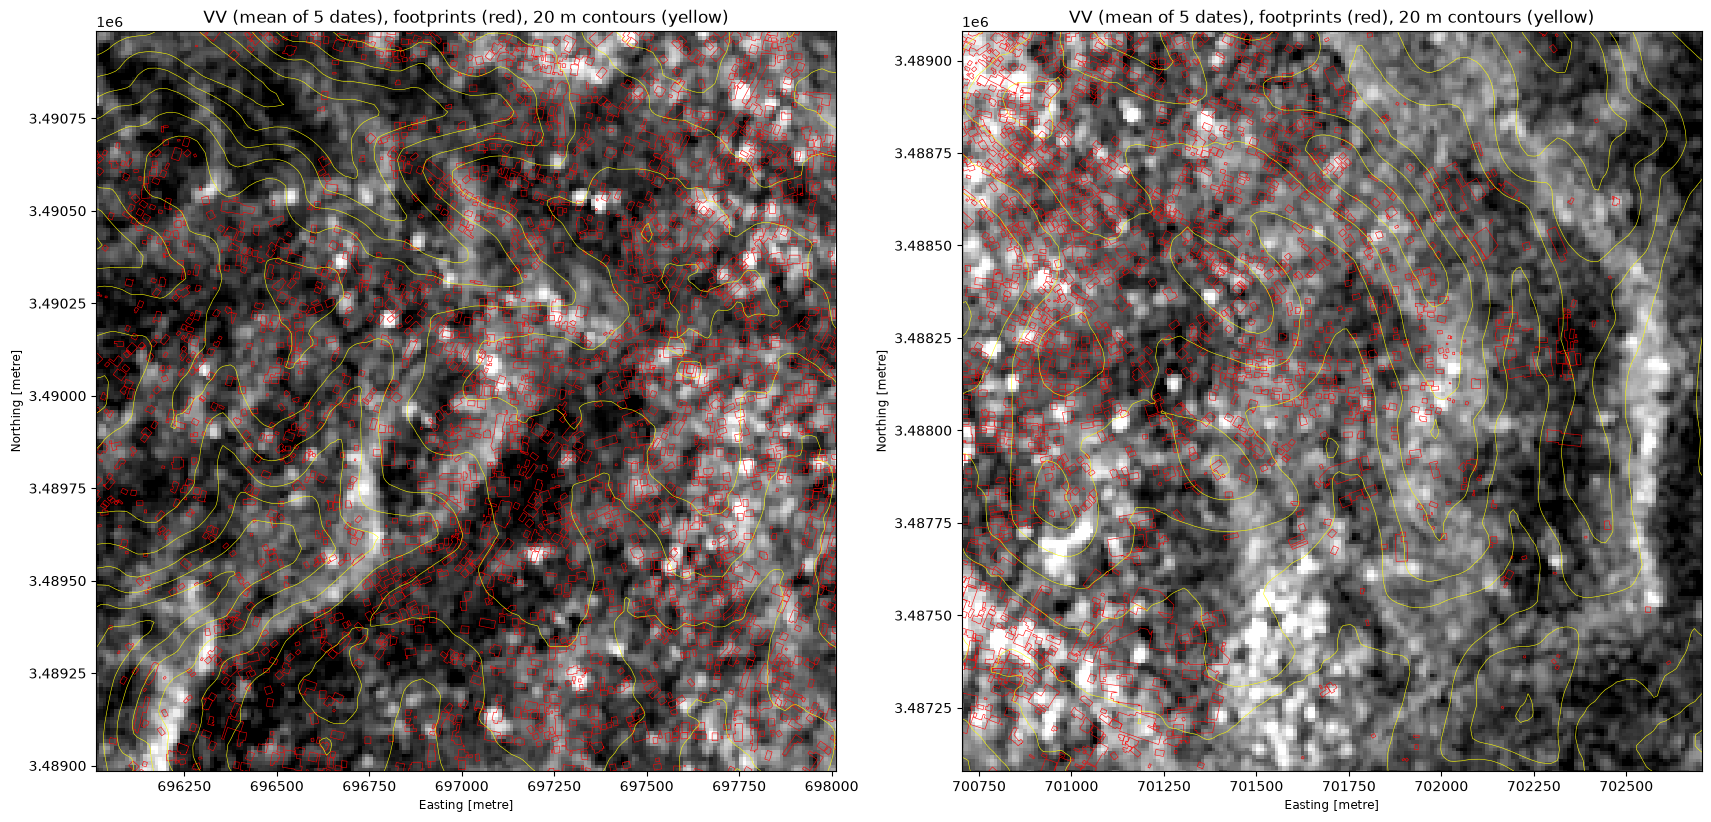

In [4]:
ext = (left, left + W10 * 10, top - H10 * 10, top)
zooms = [(BBOX[0] + 0.25 * (BBOX[2] - BBOX[0]), BBOX[1] + 0.40 * (BBOX[3] - BBOX[1])),
         (BBOX[0] + 0.60 * (BBOX[2] - BBOX[0]), BBOX[1] + 0.25 * (BBOX[3] - BBOX[1]))]
from pyproj import Transformer
to_utm = Transformer.from_crs(4326, GRID_CRS, always_xy=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5), constrained_layout=True)
for ax, (lo, la) in zip(axes, zooms):
    cx, cy = to_utm.transform(lo, la)
    ax.imshow(vv_db, extent=ext, cmap="gray", vmin=np.nanpercentile(vv_db, 2), vmax=np.nanpercentile(vv_db, 99.5))
    fp.boundary.plot(ax=ax, color="red", linewidth=0.4)
    ax.contour(np.arange(W10) * 10 + left + 5, top - np.arange(H10) * 10 - 5, height, levels=range(300, 1100, 20),
               colors="yellow", linewidths=0.4)
    ax.set_xlim(cx - 1000, cx + 1000); ax.set_ylim(cy - 1000, cy + 1000)
    ax.set_title(f"VV (mean of {len(files)} dates), footprints (red), 20 m contours (yellow)")
plt.show()

## 2. Measure

**Viewing geometry.** From a saved SLC interferogram of track D094 (pygeofetch stores, per pixel, the incidence angle and how a pixel's ground position moves per metre of height, `dlon_dh`, `dlat_dh`): the horizontal direction towards the satellite and the incidence angle θ. A point at height *h* appears displaced towards the satellite by *h* · cot θ in ellipsoid-projected radar data, so this also gives the **expected** shift per metre of height if the GRD were not terrain-corrected at all.

**Reference image.** The DEM-simulated brightness cos(local incidence) = n · ℓ (n: the ground's unit normal from the DEM, ℓ: unit vector towards the satellite), at true positions.

**Shift per tile.** Both images are band-pass filtered (speckle smoothed over ~15 m, the regional trend over ~250 m removed) and cross-correlated; the peak gives the shift of the radar image relative to the true positions (east, north, metres), refined to sub-pixel. Peaks below 0.15 are not trusted.

✅ Success: snaphu binary detected at '/usr/local/bin/snaphu'. No manual installation needed.
geometry from SLC geometry of 2026-06-06_2026-06-18: towards the satellite (east, north) = (+0.983, -0.186), incidence 32.0 deg -> uncorrected terrain displacement 1.60 m per m of height
simulated brightness: cos(local incidence) 0.61 .. 0.96


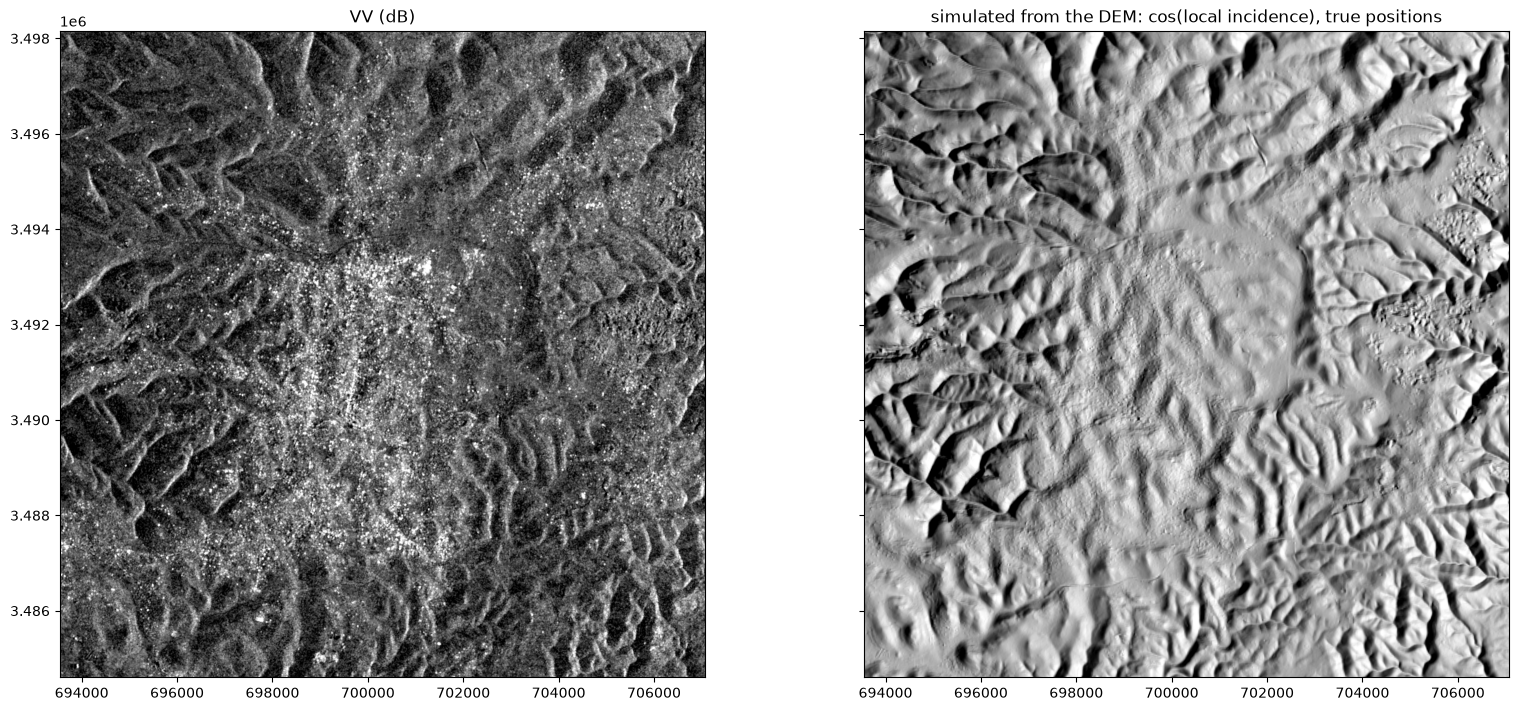

In [5]:
from pygeofetch.insar.interferogram import InterferogramResult

geom_src = "approximate defaults"
pairs = sorted(p for p in IFG_DIR.iterdir() if p.is_dir() and (p / "result.json").exists()) if IFG_DIR.exists() else []
for pdir in pairs:
    try:
        g = InterferogramResult.load(pdir).geometry
        if g is None:
            continue
        lat = g.dense("lat", dtype=np.float64)
        de = g.dense("dlon_dh", dtype=np.float64) * 111_320.0 * np.cos(np.radians(lat))   # m east per m of height
        dn = g.dense("dlat_dh", dtype=np.float64) * 110_540.0                            # m north per m of height
        d = np.array([np.nanmedian(de), np.nanmedian(dn)])
        TO_SAT_EN = tuple(-d / np.hypot(*d))          # the ground point moves AWAY from the satellite as height grows
        INCIDENCE_DEG = float(np.degrees(np.arctan(1.0 / np.hypot(*d))))                  # |d| = cot(theta)
        geom_src = f"SLC geometry of {pdir.name}"
        break
    except Exception as exc:
        print(f"  {pdir.name}: geometry not readable ({type(exc).__name__}: {exc})")
theta = np.radians(INCIDENCE_DEG)
L = np.array([TO_SAT_EN[0] * np.sin(theta), TO_SAT_EN[1] * np.sin(theta), np.cos(theta)])
print(f"geometry from {geom_src}: towards the satellite (east, north) = ({TO_SAT_EN[0]:+.3f}, {TO_SAT_EN[1]:+.3f}), "
      f"incidence {INCIDENCE_DEG:.1f} deg -> uncorrected terrain displacement {1 / np.tan(theta):.2f} m per m of height")

hz = np.where(np.isfinite(height), height, np.nanmean(height))
gy, gx = np.gradient(hz, 10.0)                       # rows run north -> south: d/dy(north) = -gy
nx, ny, nz = -gx, gy, np.ones_like(hz)
nn = np.sqrt(nx ** 2 + ny ** 2 + nz ** 2)
sim = (nx * L[0] + ny * L[1] + nz * L[2]) / nn        # cos(local incidence), true positions
print(f"simulated brightness: cos(local incidence) {np.nanpercentile(sim, 2):.2f} .. {np.nanpercentile(sim, 98):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True, sharex=True, sharey=True)
axes[0].imshow(vv_db, extent=ext, cmap="gray", vmin=np.nanpercentile(vv_db, 2), vmax=np.nanpercentile(vv_db, 99.5))
axes[0].set_title("VV (dB)")
axes[1].imshow(sim, extent=ext, cmap="gray", vmin=np.nanpercentile(sim, 2), vmax=np.nanpercentile(sim, 99.5))
axes[1].set_title("simulated from the DEM: cos(local incidence), true positions")
plt.show()

In [6]:
def highpass(a, fine=1.5, coarse=25):
    """Band-pass: speckle smoothed (fine, pixels), the regional trend removed (coarse): slopes of 50-500 m remain."""
    a = np.where(np.isfinite(a), a, np.nanmean(a))
    return gaussian_filter(a, fine) - gaussian_filter(a, coarse)


def best_shift(img, ref, max_px):
    """Shift (rows, cols) of img relative to ref maximising their normalised cross-correlation, and its value."""
    a, b = highpass(img), highpass(ref)
    taper = np.outer(np.hanning(a.shape[0]), np.hanning(a.shape[1]))     # no wrap-around at the tile edges
    a, b = (a - a.mean()) * taper, (b - b.mean()) * taper
    hh, ww = a.shape
    c = np.real(np.fft.ifft2(np.fft.fft2(a, s=(2 * hh, 2 * ww)) * np.conj(np.fft.fft2(b, s=(2 * hh, 2 * ww)))))
    c = np.fft.fftshift(c / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-12))       # c[k] = sum_x a(x) b(x - k), normalised
    h, w = c.shape
    r0, c0 = h // 2, w // 2
    win = c[r0 - max_px:r0 + max_px + 1, c0 - max_px:c0 + max_px + 1]
    i, j = np.unravel_index(np.argmax(win), win.shape)
    def sub(m, p, q):                      # parabola through three neighbours
        return 0.5 * (m - q) / (m - 2 * p + q) if (m - 2 * p + q) != 0 else 0.0
    di = sub(win[i - 1, j], win[i, j], win[i + 1, j]) if 0 < i < win.shape[0] - 1 else 0.0
    dj = sub(win[i, j - 1], win[i, j], win[i, j + 1]) if 0 < j < win.shape[1] - 1 else 0.0
    return i - max_px + di, j - max_px + dj, float(win[i, j])


tile, maxs = TILE_M // 10, MAX_SHIFT_M // 10
rows = []
for r in range(0, H10 - tile + 1, tile // 2):
    for c in range(0, W10 - tile + 1, tile // 2):
        if not np.isfinite(vv_db[r:r + tile, c:c + tile]).mean() > 0.9:
            continue
        dr, dc, peak = best_shift(vv_db[r:r + tile, c:c + tile], sim[r:r + tile, c:c + tile], maxs)
        rows.append({"row": r, "col": c, "east_m": 10 * dc, "north_m": -10 * dr, "peak": peak,
                     "height_m": float(np.nanmean(height[r:r + tile, c:c + tile])),
                     "built": float(built[r:r + tile, c:c + tile].mean())})
shifts = pd.DataFrame(rows)
shifts["towards_satellite_m"] = shifts["east_m"] * TO_SAT_EN[0] + shifts["north_m"] * TO_SAT_EN[1]
good = shifts[shifts["peak"] >= 0.15]
print(f"{len(shifts)} tiles, {len(good)} with a clear correlation peak (>= 0.15); "
      f"peak correlation median {shifts['peak'].median():.2f}" if len(shifts) else "no tile with data")
display(good.round(2))

225 tiles, 218 with a clear correlation peak (>= 0.15); peak correlation median 0.33


,row,col,east_m,north_m,peak,height_m,built,towards_satellite_m
0,0,0,137.04,-19.39,0.53,670.26,0.00,138.25
1,0,80,284.74,-30.45,0.42,749.85,0.00,285.44
2,0,160,266.11,-59.80,0.52,815.75,0.01,272.59
3,0,240,400.00,-60.88,0.44,859.34,0.01,404.35
4,0,320,333.89,-46.63,0.65,891.79,0.02,336.74
...,...,...,...,...,...,...,...,...
220,1120,800,400.00,-92.68,0.49,860.94,0.01,410.25
221,1120,880,400.00,-124.04,0.36,876.46,0.01,416.08
222,1120,960,-326.09,327.02,0.32,875.55,0.01,-381.16
223,1120,1040,384.16,-50.65,0.51,858.70,0.00,386.88


## 3. Decide

,offset at mean height (m),change per metre of height (m/m),scatter (m)
east_m,144.184,-0.873,225.090
north_m,-56.668,-0.093,143.690
towards_satellite_m,152.201,-0.841,225.826


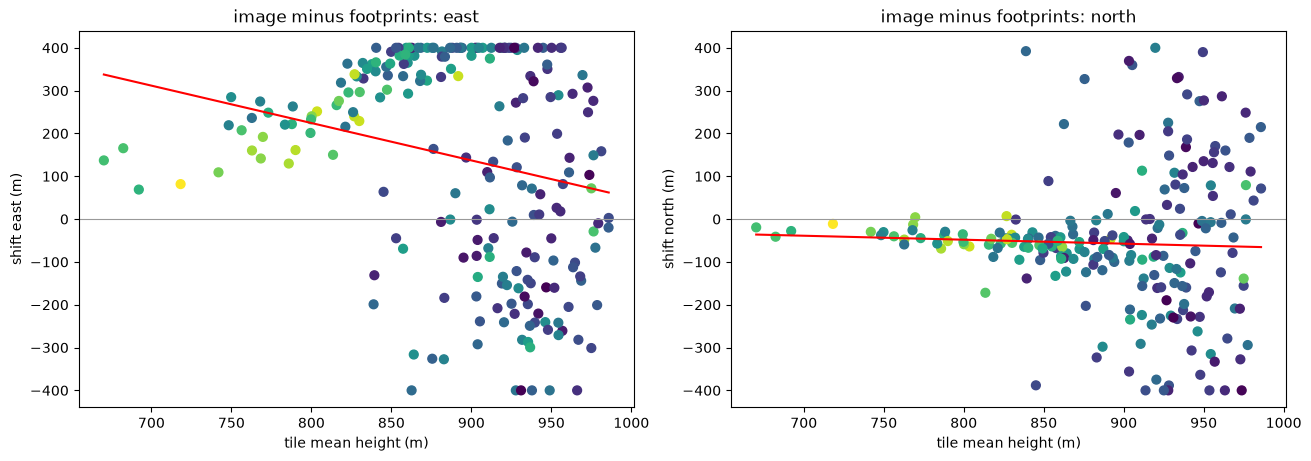

expected without any terrain correction: 1.60 m towards the satellite per m of height (relative to the height the georeferencing assumed)
offset at mean height 155 m; change with height 0.88 m per m (over this city's 316 m height range: 277 m)
-> the shift changes with height: terrain distortion. Section 4 needs a terrain correction (send these numbers).


In [7]:
if len(good) >= 3:
    A = np.c_[np.ones(len(good)), good["height_m"] - good["height_m"].mean()]
    w = good["peak"].to_numpy()
    fit = {}
    for comp in ("east_m", "north_m", "towards_satellite_m"):
        coef, *_ = np.linalg.lstsq(A * w[:, None], good[comp].to_numpy() * w, rcond=None)
        resid = good[comp].to_numpy() - A @ coef
        fit[comp] = {"offset at mean height (m)": coef[0], "change per metre of height (m/m)": coef[1],
                     "scatter (m)": float(np.sqrt(np.average(resid ** 2, weights=w)))}
    display(pd.DataFrame(fit).T.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
    for ax, comp in zip(axes, ("east_m", "north_m")):
        ax.scatter(good["height_m"], good[comp], c=good["peak"], cmap="viridis", s=40)
        hh = np.linspace(good["height_m"].min(), good["height_m"].max(), 10)
        ax.plot(hh, fit[comp]["offset at mean height (m)"] + fit[comp]["change per metre of height (m/m)"] * (hh - good["height_m"].mean()), "r-")
        ax.axhline(0, color="0.6", lw=0.8); ax.set_xlabel("tile mean height (m)"); ax.set_ylabel(f"shift {comp.split('_')[0]} (m)")
        ax.set_title(f"image minus footprints: {comp.split('_')[0]}")
    plt.show()
    print(f"expected without any terrain correction: {1 / np.tan(theta):.2f} m towards the satellite per m of height "
          f"(relative to the height the georeferencing assumed)")
    e, n = fit["east_m"], fit["north_m"]
    slope = np.hypot(e["change per metre of height (m/m)"], n["change per metre of height (m/m)"])
    offset = np.hypot(e["offset at mean height (m)"], n["offset at mean height (m)"])
    print(f"offset at mean height {offset:.0f} m; change with height {slope:.2f} m per m "
          f"(over this city's {good['height_m'].max() - good['height_m'].min():.0f} m height range: "
          f"{slope * (good['height_m'].max() - good['height_m'].min()):.0f} m)")
    if slope * (good['height_m'].max() - good['height_m'].min()) > 20:
        print("-> the shift changes with height: terrain distortion. Section 4 needs a terrain correction (send these numbers).")
    elif offset > 15:
        print("-> one constant offset: a simple shift in section 4 corrects it (send these numbers).")
    else:
        print("-> aligned to within about one to two pixels: no correction needed.")
else:
    print("fewer than 3 tiles with a clear peak: send the figure of section 1 instead")